<a href="https://colab.research.google.com/github/beilak/qdev/blob/main/first_step/Q_Hello_World.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
from qiskit import QuantumCircuit
from qiskit_aer.primitives import SamplerV2
from qiskit.visualization import plot_histogram
from dotenv import load_dotenv



# from qiskit import Aer, transpile
# import matplotlib.pyplot as plt
# from qiskit_ibm_provider import IBMProvider
# from qiskit_ibm_provider.ibm_backend import IBMBackend
# from qiskit_aer.backends.qasm_simulator import QasmSimulator
# from qiskit_aer.jobs.aerjob import AerJob

load_dotenv()


True

In [4]:
TOKEN: str | None = os.getenv("IBM_QCLOUD_TOKEN", None)
if not TOKEN:
    raise ValueError("And where is your token?")


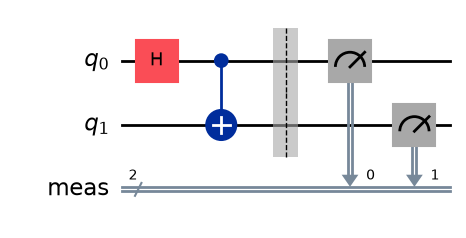

In [5]:
qc: QuantumCircuit = QuantumCircuit(2) # Circuit

qc.h(0) # Hadamard gate
qc.cx(0, 1) # Controlled not gate

qc.measure_all()
qc.draw(output="mpl")


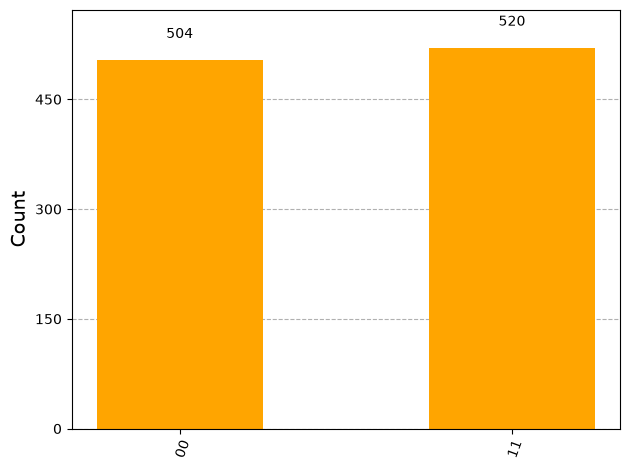

In [6]:
# SIMULATOR
from qiskit_aer.primitives import SamplerV2
from qiskit.visualization import plot_histogram

sampler = SamplerV2()
job = sampler.run([qc], shots=1024)
sim_result = job.result()
sim_counts = sim_result[0].data.meas.get_counts()


plot_histogram(sim_counts, color="orange")


### Run in real hardware 

In [7]:
from qiskit_ibm_runtime import QiskitRuntimeService

#### Prepare

In [9]:
service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=TOKEN,
    instance='auto',
)

qiskit_runtime_service._discover_account:WARNING:2026-10-13 18:52:02,322: Loading account with the given token. A saved account will not be used.


In [11]:

from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as IBMSampler

# 1. Select a real quantum processor
backend = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=2,
)
print(f"Selected QPU: {backend.name}")



Selected QPU: ibm_marrakesh


In [12]:
# 2. Adapt the circuit to IBM hardware
pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1,
)
isa_qc = pm.run(qc)


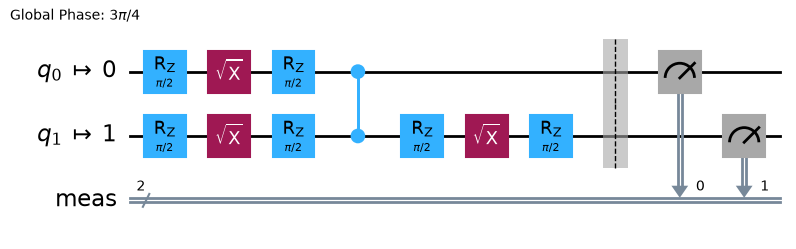

In [22]:
isa_qc.draw(output="mpl")

In [13]:

# 3. Execute on a real quantum computer
sampler = IBMSampler(mode=backend)
job = sampler.run([isa_qc], shots=1024)

print(f"Job ID: {job.job_id()}")


Job ID: db75vbur6oqs7386r6tg


In [14]:

# 4. Retrieve results
result = job.result()
ibm_counts = result[0].data.meas.get_counts()

print(f"IBM results: {ibm_counts}")


IBM results: {'10': 24, '11': 498, '00': 496, '01': 6}


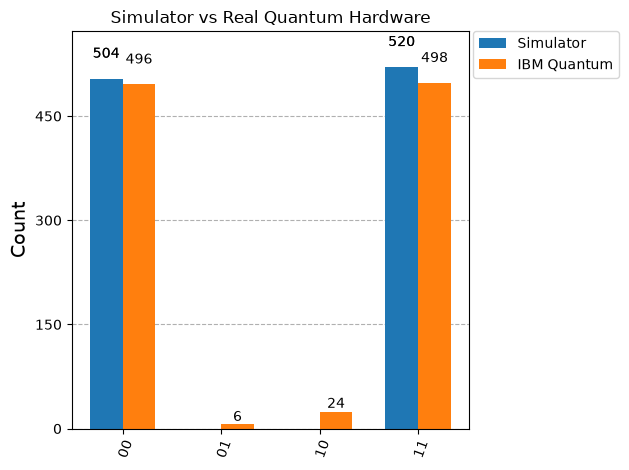

In [16]:

# 5. Compare simulation and real hardware
import matplotlib.pyplot as plt

plot_histogram(
    [sim_counts, ibm_counts],
    legend=["Simulator", "IBM Quantum"],
    title="Simulator vs Real Quantum Hardware",
)